# Ejercicio Python de K-means

-------

Tomado de: https://www.aprendemachinelearning.com/k-means-en-python-paso-a-paso/

Modificaciones y ejecucion: Carlos Francisco Montoya Urzua

Realizaremos un ejercicio de prueba para comprender como funciona este algoritmo

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min

%matplotlib inline
from mpl_toolkits.mplot3d import Axes3D
plt.rcParams['figure.figsize'] = (16, 9)
plt.style.use('ggplot')

## Cargamos los datos de entrada del archivo csv

In [24]:
dataframe = pd.read_csv(r"analisis.csv")
dataframe.head()

,usuario,op,co,ex,ag,ne,wordcount,categoria
0,3gerardpique,34.297953,28.148819,41.948819,29.370315,9.841575,37.0945,7
1,aguerosergiokun,44.986842,20.525865,37.938947,24.279098,10.362406,78.7970,7
2,albertochicote,41.733854,13.745417,38.999896,34.645521,8.836979,49.2604,4
3,AlejandroSanz,40.377154,15.377462,52.337538,31.082154,5.032231,80.4538,2
4,alfredocasero1,36.664677,19.642258,48.530806,31.138871,7.305968,47.0645,4


In [25]:
dataframe.describe()

,op,co,ex,ag,ne,wordcount,categoria
count,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000,140.000000
mean,44.414591,22.977135,40.764428,22.918528,8.000098,98.715484,4.050000
std,8.425723,5.816851,7.185246,7.657122,3.039248,44.714071,2.658839
min,30.020465,7.852756,18.693542,9.305985,1.030213,5.020800,1.000000
25%,38.206484,19.740299,36.095722,17.050993,6.086144,66.218475,2.000000
50%,44.507091,22.466718,41.457492,21.384554,7.839722,94.711400,3.500000
75%,49.365923,26.091606,45.197769,28.678866,9.758189,119.707925,7.000000
max,71.696129,49.637863,59.824844,40.583162,23.978462,217.183200,9.000000


In [26]:
#vemos cuantos usuarios hay de cada categoria
print(dataframe.groupby('categoria').size())

categoria
1    27
2    34
3     9
4    19
5     4
6     8
7    17
8    16
9     6
dtype: int64


Las categorias son: 1-actores 2-cantantes 3-modelo 4-TV 5-radio 6-tecnología 7-deportes 8-politica 9-escritor

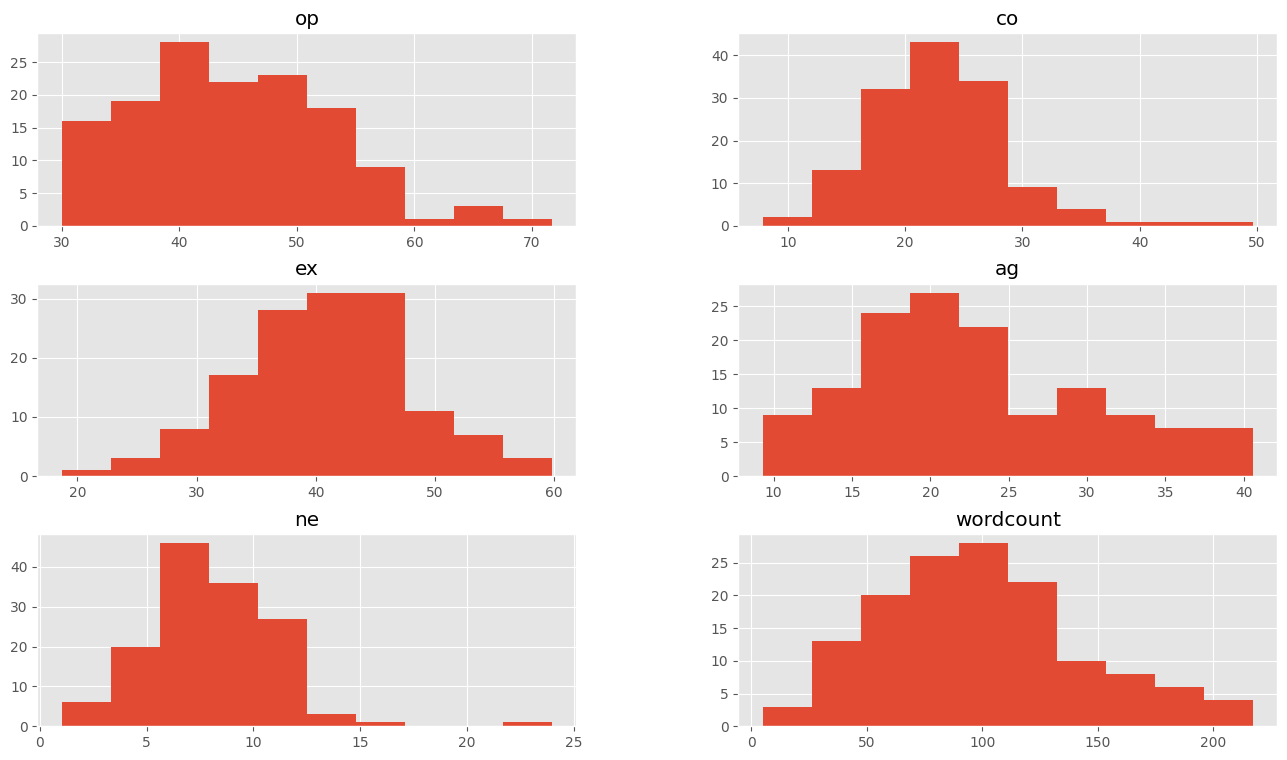

In [11]:
#dataframe.drop(['categoria'],1).hist()
dataframe.drop('categoria', axis=1).hist()
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


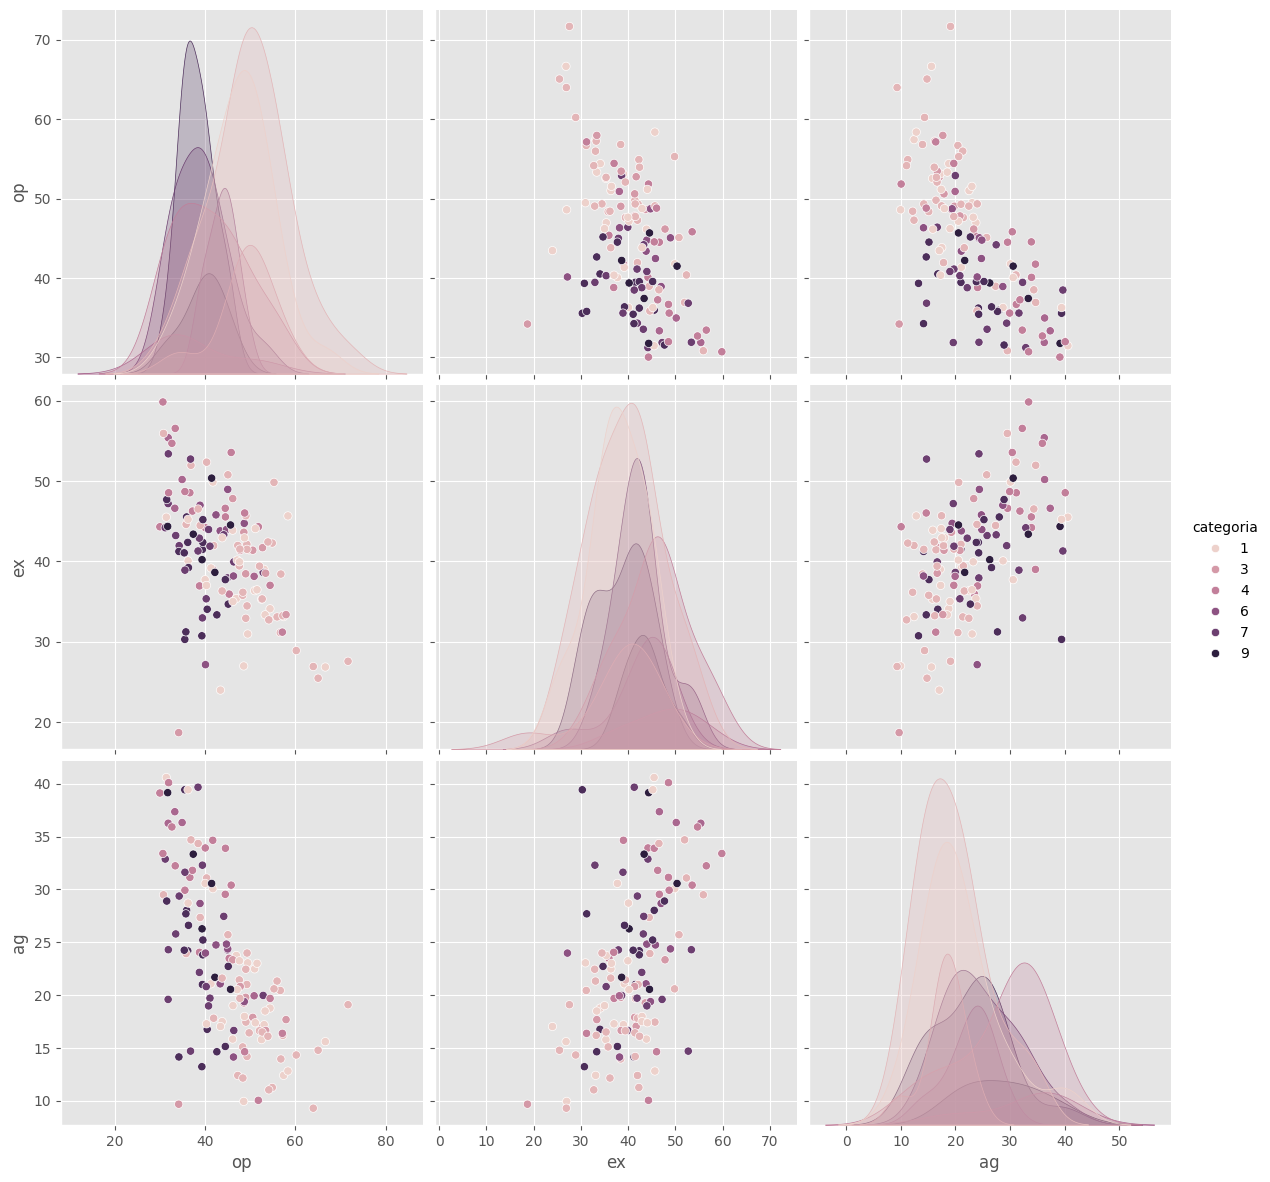

In [12]:
sb.pairplot(dataframe.dropna(), hue='categoria',size=4,vars=["op","ex","ag"],kind='scatter')

## Creamos el modelo

In [13]:
#Para el ejercicio, sólo seleccionamos 3 dimensiones, para poder graficarlo
X = np.array(dataframe[["op","ex","ag"]])
y = np.array(dataframe['categoria'])
X.shape

(140, 3)

In [46]:
fig = plt.figure()
ax = Axes3D(fig)
colores=['blue','red','green','blue','cyan','yellow','orange','black','pink','brown','purple']
#NOTA: asignamos la posición cero del array repetida pues las categorias comienzan en id 1.
asignar=[]
for row in y:
    asignar.append(colores[row])
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=asignar,s=60)

<Figure size 1600x900 with 0 Axes>

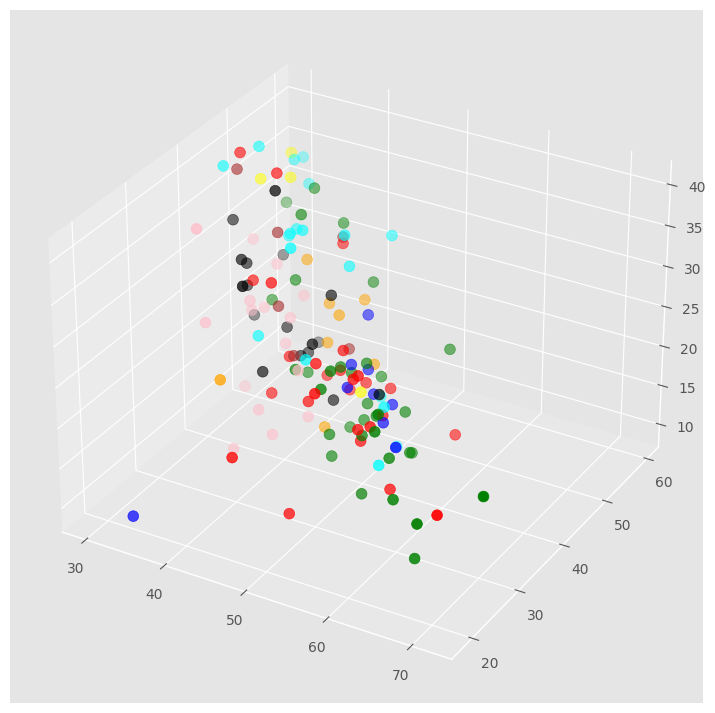

In [47]:
fig = plt.figure()

# EL CAMBIO CLAVE: Así se crean los gráficos 3D ahora
ax = fig.add_subplot(projection='3d')

colores = ['blue', 'red', 'green', 'blue', 'cyan', 'yellow', 'orange', 'black', 'pink', 'brown', 'purple']

# Optimizado: Una lista de comprensión hace lo mismo que tu bucle 'for' en una sola línea
asignar = [colores[row] for row in y]

ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=asignar, s=60)
plt.show()


# Buscamos el valor K

In [27]:
Nc = range(1, 20)
kmeans = [KMeans(n_clusters=i) for i in Nc]
kmeans

[KMeans(n_clusters=1),
 KMeans(n_clusters=2),
 KMeans(n_clusters=3),
 KMeans(n_clusters=4),
 KMeans(n_clusters=5),
 KMeans(n_clusters=6),
 KMeans(n_clusters=7),
 KMeans(),
 KMeans(n_clusters=9),
 KMeans(n_clusters=10),
 KMeans(n_clusters=11),
 KMeans(n_clusters=12),
 KMeans(n_clusters=13),
 KMeans(n_clusters=14),
 KMeans(n_clusters=15),
 KMeans(n_clusters=16),
 KMeans(n_clusters=17),
 KMeans(n_clusters=18),
 KMeans(n_clusters=19)]

In [28]:
score = [kmeans[i].fit(X).score(X) for i in range(len(kmeans))]
score

[-25194.03935276632,
 -12632.031536945233,
 -10292.659714088213,
 -8558.652830959967,
 -7044.6044104426355,
 -6941.519078833923,
 -5745.115973994465,
 -5294.179628927684,
 -4748.675117195588,
 -4354.988461914013,
 -3896.763458990087,
 -3848.7379330076,
 -3280.307995210149,
 -3179.9644856365517,
 -2979.1212658141853,
 -2694.9326954287358,
 -2475.657847982741,
 -2508.545258644932,
 -2492.9771326748873]

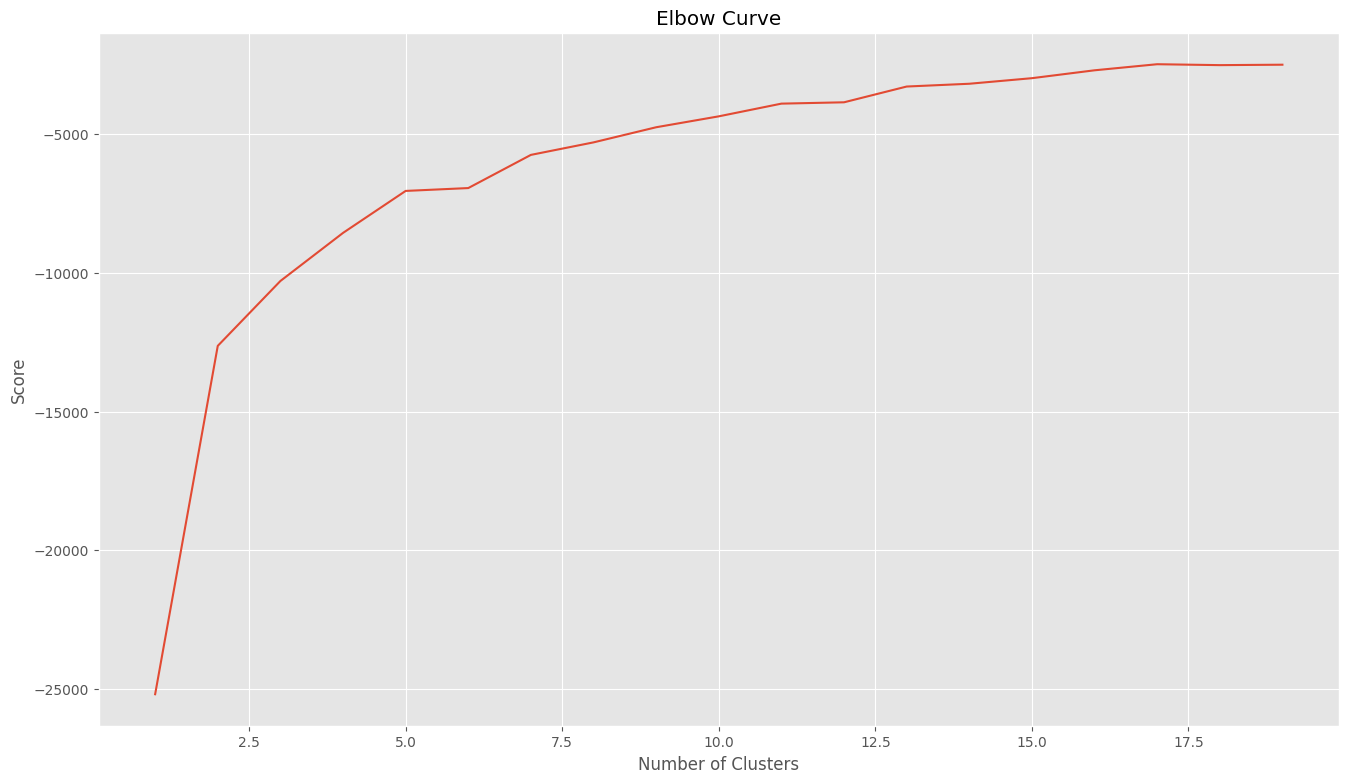

In [29]:
plt.plot(Nc,score)
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.title('Elbow Curve')
plt.show()

In [30]:
# Para el ejercicio, elijo 5 como un buen valor de K. Pero podría ser otro.
kmeans = KMeans(n_clusters=5).fit(X)
centroids = kmeans.cluster_centers_
print(centroids)

[[47.31064362 38.44783975 18.50202015]
 [35.52574456 52.33541    32.17281744]
 [36.44741195 41.47186725 34.4887694 ]
 [57.63426538 32.95310414 15.51772971]
 [39.58134289 44.05605836 23.59178618]]


In [31]:
# Obtenemos las etiquetas de cada punto de nuestros datos
labels = kmeans.predict(X)
# Obtenemos los centroids
C = kmeans.cluster_centers_
colores=['red','green','blue','cyan','yellow']
asignar=[]
for row in labels:
    asignar.append(colores[row])

fig = plt.figure()
ax = Axes3D(fig)
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=asignar,s=60)
ax.scatter(C[:, 0], C[:, 1], C[:, 2], marker='*', c=colores, s=1000)

<Figure size 1600x900 with 0 Axes>

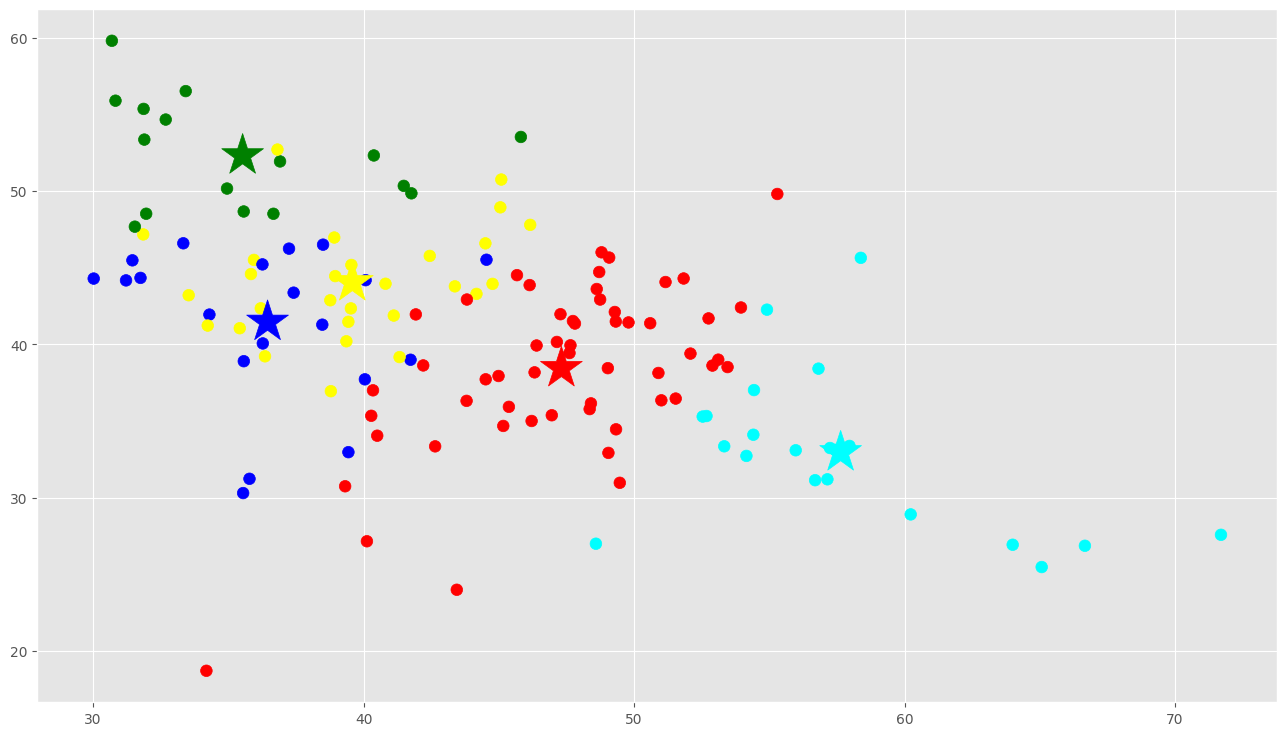

In [32]:
# Hacemos una proyección a 2D con los diversos ejes
f1 = dataframe['op'].values
f2 = dataframe['ex'].values

plt.scatter(f1, f2, c=asignar, s=70)
plt.scatter(C[:, 0], C[:, 1], marker='*', c=colores, s=1000)
plt.show()

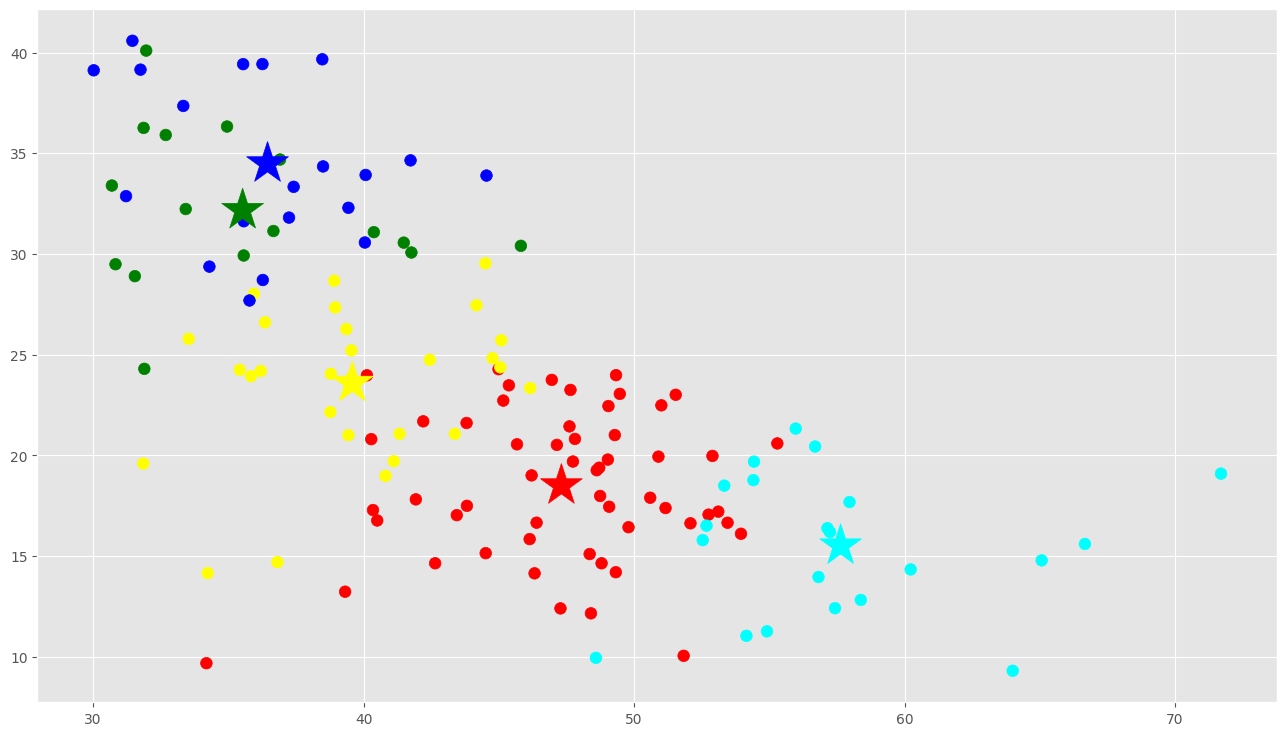

In [34]:
# Hacemos una proyección a 2D con los diversos ejes
f1 = dataframe['op'].values
f2 = dataframe['ag'].values

plt.scatter(f1, f2, c=asignar, s=70)
plt.scatter(C[:, 0], C[:, 2], marker='*', c=colores, s=1000)
plt.show()

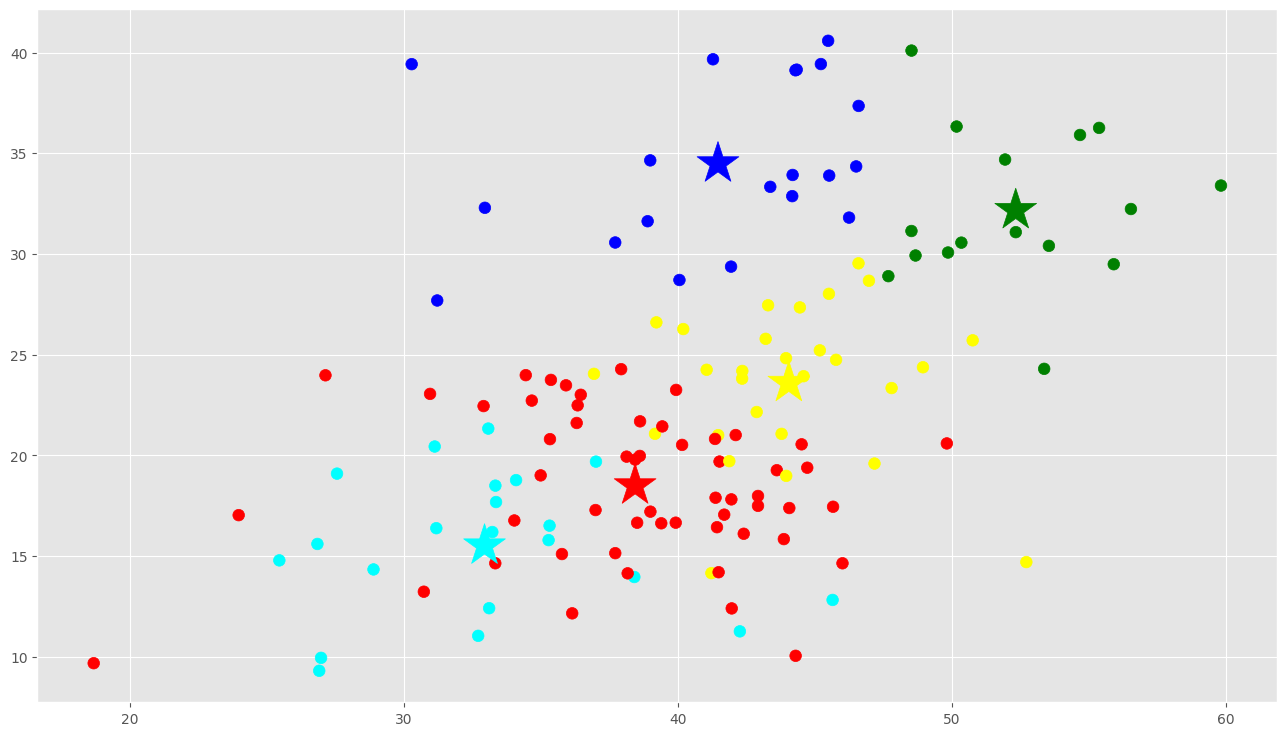

In [35]:
f1 = dataframe['ex'].values
f2 = dataframe['ag'].values

'''
# este codigo comentado agrega las categorias sobre cada punto
for label, x, y in zip(dataframe['categoria'].values, f1, f2):
    plt.annotate(
        label,
        xy=(x, y), xytext=(-10, 10),
        textcoords='offset points', ha='right', va='bottom',
        bbox=dict(boxstyle='round,pad=0.5', fc='yellow', alpha=0.5),
        arrowprops=dict(arrowstyle = '->', connectionstyle='arc3,rad=0'))
'''
plt.scatter(f1, f2, c=asignar, s=70)
plt.scatter(C[:, 1], C[:, 2], marker='*', c=colores, s=1000)
plt.show()

In [38]:
# contamos cuantos usuarios hay en cada grupo
copy =  pd.DataFrame()
copy['usuario']=dataframe['usuario'].values
copy['categoria']=dataframe['categoria'].values
copy['label'] = labels;
cantidadGrupo =  pd.DataFrame()
cantidadGrupo['color']=colores
cantidadGrupo['cantidad']=copy.groupby('label').size()
cantidadGrupo

,color,cantidad
0,red,55
1,green,16
2,blue,20
3,cyan,21
4,yellow,28


In [37]:
# Veamos cuantos usuarios en cada categoria hay en el grupo 0
group_referrer_index = copy['label'] ==0
group_referrals = copy[group_referrer_index]

diversidadGrupo =  pd.DataFrame()
diversidadGrupo['categoria']=[0,1,2,3,4,5,6,7,8,9]
diversidadGrupo['cantidad']=group_referrals.groupby('categoria').size()
diversidadGrupo

,categoria,cantidad
0,0,NaN
1,1,14.0
2,2,16.0
3,3,7.0
4,4,3.0
5,5,1.0
6,6,3.0
7,7,4.0
8,8,5.0
9,9,2.0


In [39]:
#imprimimos en pantalla los usuarios con categoria 2 del grupo
for index, row in group_referrals.iterrows():
    if row["categoria"] == 2:
        print (row["usuario"], row["categoria"],row["label"])

AvrilLavigne 2 0
britneyspears 2 0
celinedion 2 0
Courtney 2 0
Fergie 2 0
IamStevenT 2 0
jtimberlake 2 0
justinbieber 2 0
kanyewest 2 0
katyperry 2 0
KidRock 2 0
ladygaga 2 0
LennyKravitz 2 0
shakira 2 0
taylorswift13 2 0
thelittleidiot 2 0


In [41]:
#vemos el representante del grupo, el usuario cercano a su centroid
closest, _ = pairwise_distances_argmin_min(kmeans.cluster_centers_, X)
closest

array([ 29,  20, 111,  75,  64])

In [42]:
users=dataframe['usuario'].values
for row in closest:
    print(users[row])

CindyCrawford
CarlosAuryn
perezreverte
JLo
ierrejon


In [43]:
#miramos los usuarios del grupo 0
for index, row in copy.iterrows():
    if row["label"] == 0:
        print (row["usuario"], row["categoria"],row["label"])

aguerosergiokun 7 0
andyroddick 7 0
AngelAlessandra 3 0
AvrilLavigne 2 0
BarRefaeli 3 0
britneyspears 2 0
carmenelectra 3 0
Carrie_Br4dshaw 3 0
celinedion 2 0
cesarmillan 4 0
CindyCrawford 3 0
CourteneyCox 1 0
Courtney 2 0
Cristiano 7 0
Diane_Keaton 1 0
epunset 6 0
EvaLongoria 3 0
Fergie 2 0
GwynethPaltrow 1 0
heidiklum 3 0
HillaryClinton 8 0
IamStevenT 2 0
jiminhofe 8 0
jimlangevin 8 0
jimmyfallon 4 0
jk_rowling 9 0
jtimberlake 2 0
justdemi 1 0
justinbieber 2 0
kanyewest 2 0
katyperry 2 0
KevinSpacey 1 0
KidRock 2 0
kobebryant 7 0
ladygaga 2 0
LennyKravitz 2 0
LeoDiCaprio 1 0
martinvars 6 0
MelanieGriffith 1 0
MileyCyrus 1 0
PaulaMeliveo 5 0
paulocoelho 9 0
RealHughJackman 1 0
Rep_Hunter 8 0
SarahPalinUSA 8 0
shakira 2 0
SJP 1 0
SSantiagosegura 1 0
stevewoz 6 0
taylorswift13 2 0
TheEllenShow 4 0
thelittleidiot 2 0
TheReal_Jlh 1 0
tomhanks 1 0
ZacEfron 1 0


# Clasificación de nuevos registros

In [45]:
X_new = np.array([[45.92,57.74,15.66]]) #davidguetta personality traits
new_labels = kmeans.predict(X_new)
print(new_labels)

#NOTA: en el array podemos poner más de un array para evaluar a varios usuarios nuevos a la vez

[4]


NOTA FINAL: Los resultados obtenidos pueden varias de ejecución en ejecución pues al inicializar aleatoriamente los centroids, podemos obtener grupos distintos o los mismos pero en distinto orden y color

## PREDICCIONES AGREGADAS PARA PROBAR EL MODELO

In [50]:
#NUEVOS USUARIOS AGREGADOS COMO PREDICCION
X_new = np.array([[70, 100, 20],		#BRITNEY SPEARS
				   [91.5, 66.8, 99.1],	#KATTY PERRY
				   [32.9, 11.8, 66.7]])	#INDILA
new_labels = kmeans.predict(X_new)
print(new_labels)

#NOTA: en el array podemos poner más de un array para evaluar a varios usuarios nuevos a la vez

[1 1 2]


El modelo indica que:

Britney Spears y Katty Perry pertenecen a la categoria 1

Indila pertenece a la categoria 2